# JS11 - Lab Assignment
## Peningkatan CNN CIFAR-10 dan Klasifikasi MNIST

Ada dua tugas pada jobsheet:

1. Memodifikasi model dari Lab 2 agar akurasi uji CIFAR-10 melebihi 80%.
2. Membangun CNN untuk klasifikasi dataset MNIST.

Model Lab 2 memakai tiga convolutional layer tanpa augmentasi dan tanpa regularisasi, sehingga
akurasi ujinya berhenti di 68.45%. Bagian A memperbaiki hal tersebut dengan empat perubahan:
augmentasi data, batch normalization, dropout, dan arsitektur yang lebih dalam. Bagian B
menerapkan pola CNN yang sama pada MNIST, dataset yang jauh lebih mudah karena hanya ada satu
objek digit di tengah citra.

## Part A - CIFAR-10 with Test Accuracy Above 80%

### Step 1 - Import Libraries and Load Data

Data dimuat dan dinormalisasi sama seperti Lab 2. Seed dikunci agar hasil dapat direproduksi.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
keras.utils.set_random_seed(SEED)

(train_images, train_labels), (test_images, test_labels) = keras.datasets.cifar10.load_data()
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print('Data latih :', train_images.shape, train_labels.shape)
print('Data uji   :', test_images.shape, test_labels.shape)

Data latih : (50000, 32, 32, 3) (50000, 1)
Data uji   : (10000, 32, 32, 3) (10000, 1)


### Step 2 - Data Augmentation Pipeline

Augmentasi hanya diterapkan pada data latih. Flip horizontal aman untuk CIFAR-10 karena objek
seperti mobil, kapal, atau hewan tetap dikenali saat dicerminkan. Translasi dan zoom membuat model
lebih tahan terhadap pergeseran posisi objek.

**Rotasi sengaja tidak dipakai.** Percobaan pertama memakai `RandomRotation(0.1)`. Pada Keras 3,
argumen `factor` layer tersebut adalah fraksi dari 2 pi, bukan derajat, sehingga 0.1 berarti
rotasi sampai 36 derajat. Akibatnya akurasi latih epoch pertama hanya 0.3430, lebih rendah
daripada model Lab 2 tanpa augmentasi (0.4572). Objek CIFAR-10 seperti kapal, truk, dan pesawat
punya orientasi tegak yang informatif, jadi memutar citra sampai 36 derajat merusak sinyal
tersebut. Versi ini hanya memakai transformasi yang tidak mengubah orientasi objek.

In [2]:
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip('horizontal'),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomZoom(0.1),
    ],
    name='data_augmentation',
)

train_ds = (
    tf.data.Dataset.from_tensor_slices((train_images, train_labels))
    .shuffle(10_000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (data_augmentation(x, training=True), y),
         num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((test_images, test_labels))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print('Jumlah batch latih:', len(train_ds))
print('Jumlah batch uji  :', len(test_ds))

Jumlah batch latih: 391
Jumlah batch uji  : 79


### Step 3 - Improved CNN Architecture

Perubahan dibanding model Lab 2:

1. **Batch normalization** setelah setiap convolutional layer. Distribusi aktivasi dijaga stabil,
   sehingga pelatihan dengan learning rate 0.001 lebih aman dan konvergensi lebih cepat.
2. **Dua convolutional layer pada blok pertama dan kedua**. Fitur level rendah dipelajari lebih
   kaya sebelum resolusi diturunkan oleh pooling.
3. **Dropout ringan** dengan tingkat yang meningkat (0.1, 0.2, 0.3, lalu 0.3 sebelum output).
   Tingkat dropout yang terlalu besar (0.5 sebelum output) terbukti membuat model underfitting
   pada percobaan pertama, karena kapasitas jaringan ini masih terbatas.
4. **Blok yang lebih lebar** (32, 64, 128 filter) agar kapasitas model cukup untuk 10 kelas.
5. **Flatten dan dense 128 tetap dipakai** karena peta fitur akhir berukuran 4x4x128, sehingga
   vektor hasil flatten hanya 2048 elemen dan dense layer tidak menjadi terlalu besar.

Semua convolutional layer memakai `padding='same'` supaya resolusi hanya turun di pooling.

In [3]:
def build_improved_cnn():
    model = keras.Sequential(name='cifar10_improved_cnn')

    model.add(layers.Conv2D(32, (3, 3), padding='same', use_bias=False,
                            input_shape=(32, 32, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(32, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.1))

    model.add(layers.Conv2D(64, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(64, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))

    model.add(layers.Conv2D(128, (3, 3), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10))

    return model


model = build_improved_cnn()
model.summary()

D:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "cifar10_improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 404,330 (1.54 MB)

 Trainable params: 403,434 (1.54 MB)

 Non-trainable params: 896 (3.50 KB)

### Step 4 - Compile and Train

Optimizer Adam dengan **cosine decay** dari learning rate 0.001 turun ke 1e-5 selama 20 epoch.
Jadwal ini memberi learning rate besar di awal untuk bergerak cepat, lalu mengecil secara halus
di akhir supaya model sempat masuk ke minimum yang lebih baik.

`EarlyStopping` dipasang dengan `patience=EPOCHS`, jadi tidak akan menghentikan pelatihan lebih
awal. Fungsinya hanya `restore_best_weights=True`, yaitu mengembalikan bobot dari epoch dengan
akurasi validasi terbaik setelah 20 epoch selesai. Pelatihan memakan sekitar 40 menit pada CPU.

In [4]:
EPOCHS = 20

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOCHS * len(train_ds),
    alpha=0.01,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=EPOCHS, restore_best_weights=True, verbose=1
    ),
]

start = time.time()
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=2,
)
elapsed = time.time() - start

print(f'Waktu pelatihan: {elapsed:.1f} detik ({elapsed / 60:.1f} menit)')
print(f'Epoch berjalan  : {len(history.history["loss"])}')

Epoch 1/20


391/391 - 153s - 391ms/step - accuracy: 0.4313 - loss: 1.5786 - val_accuracy: 0.3166 - val_loss: 2.0633


Epoch 2/20


391/391 - 142s - 364ms/step - accuracy: 0.5646 - loss: 1.2067 - val_accuracy: 0.5141 - val_loss: 1.4189


Epoch 3/20


391/391 - 202s - 516ms/step - accuracy: 0.6310 - loss: 1.0408 - val_accuracy: 0.6075 - val_loss: 1.1028


... (32 outputs left out)

Epoch 20/20


391/391 - 142s - 362ms/step - accuracy: 0.8000 - loss: 0.5680 - val_accuracy: 0.8143 - val_loss: 0.5367


Restoring model weights from the end of the best epoch: 19.


Waktu pelatihan: 3004.0 detik (50.1 menit)
Epoch berjalan  : 20


### Step 5 - Training Curves

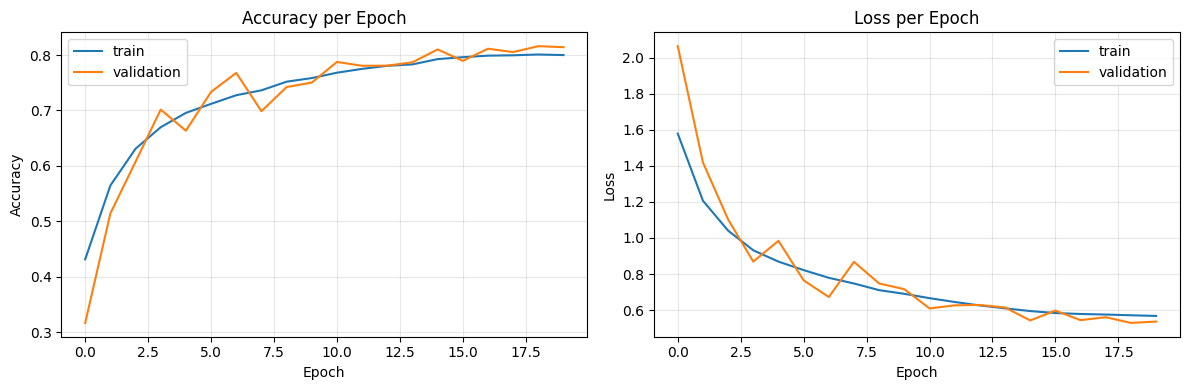

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='validation')
axes[0].set_title('Accuracy per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='validation')
axes[1].set_title('Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Step 6 - Evaluation on the Test Set

Akurasi total dihitung pada 10.000 citra uji. Confusion matrix dan metrik per kelas dipakai
untuk melihat kelas mana yang paling sering tertukar.

In [6]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f'Test loss     : {test_loss:.4f}')
print(f'Test accuracy : {test_acc:.4f}')

Test loss     : 0.5295
Test accuracy : 0.8161


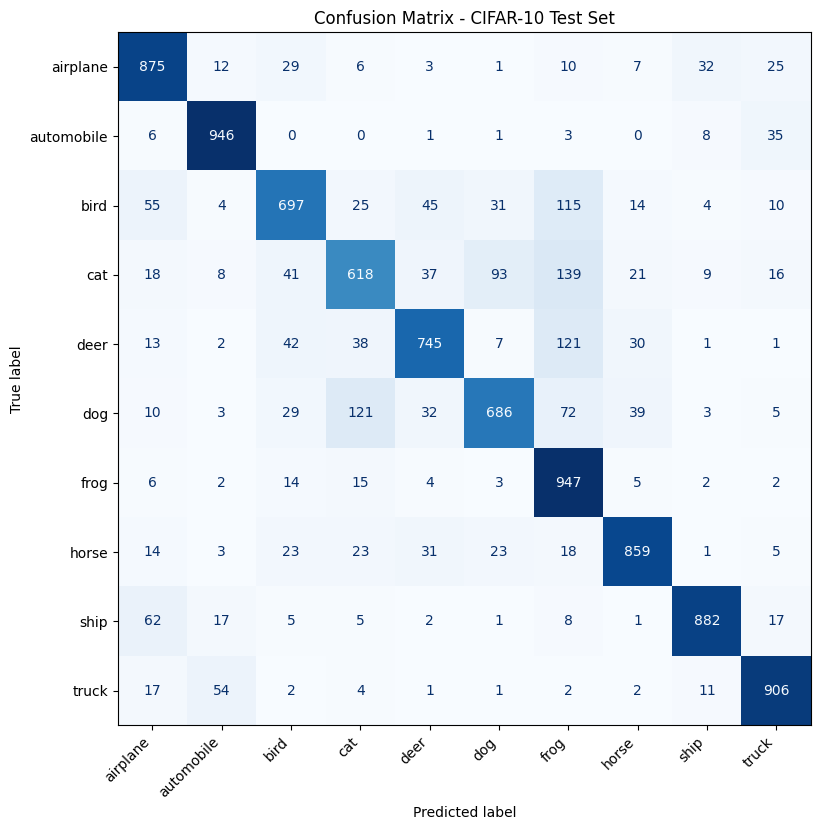

              precision    recall  f1-score   support

    airplane     0.8132    0.8750    0.8430      1000
  automobile     0.9001    0.9460    0.9225      1000
        bird     0.7902    0.6970    0.7407      1000
         cat     0.7228    0.6180    0.6663      1000
        deer     0.8269    0.7450    0.7838      1000
         dog     0.8099    0.6860    0.7428      1000
        frog     0.6599    0.9470    0.7778      1000
       horse     0.8783    0.8590    0.8686      1000
        ship     0.9255    0.8820    0.9032      1000
       truck     0.8865    0.9060    0.8961      1000

    accuracy                         0.8161     10000
   macro avg     0.8213    0.8161    0.8145     10000
weighted avg     0.8213    0.8161    0.8145     10000



In [7]:
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_labels.ravel()

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix - CIFAR-10 Test Set')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

In [8]:
for cls, name in enumerate(class_names):
    mask = y_true == cls
    print(f'{name:11s}: {accuracy_score(y_true[mask], y_pred[mask]):.4f} ({mask.sum()} citra)')

airplane   : 0.8750 (1000 citra)
automobile : 0.9460 (1000 citra)
bird       : 0.6970 (1000 citra)
cat        : 0.6180 (1000 citra)
deer       : 0.7450 (1000 citra)
dog        : 0.6860 (1000 citra)
frog       : 0.9470 (1000 citra)
horse      : 0.8590 (1000 citra)
ship       : 0.8820 (1000 citra)
truck      : 0.9060 (1000 citra)


### Step 7 - Inspect Misclassified Images

Kesalahan model biasanya terjadi pada citra dengan objek kecil, sudut pandang tidak biasa, atau
kelas yang memang mirip, misalnya cat dan dog, automobile dan truck.

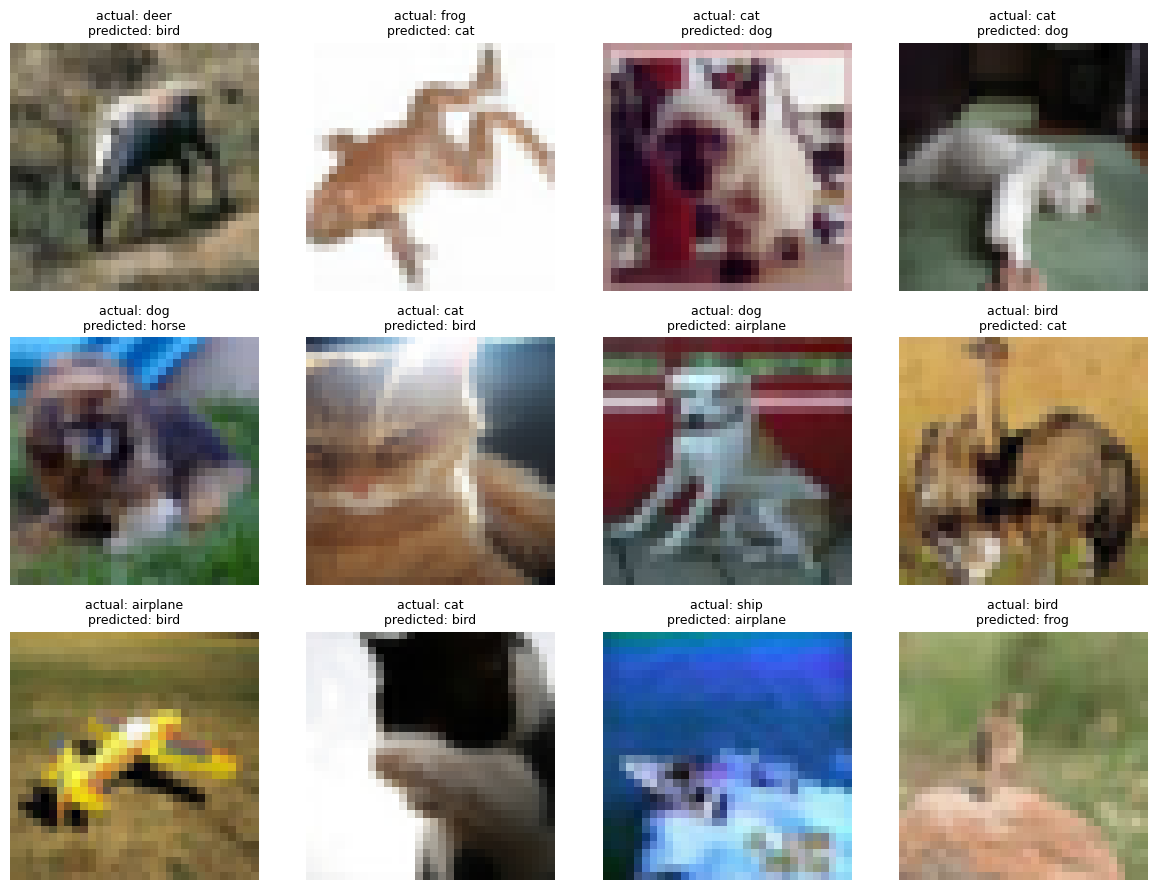

In [9]:
wrong = np.where(y_pred != y_true)[0]
rng = np.random.default_rng(SEED)
sample = rng.choice(wrong, size=12, replace=False)

plt.figure(figsize=(12, 9))
for i, idx in enumerate(sample):
    ax = plt.subplot(3, 4, i + 1)
    ax.imshow(test_images[idx])
    ax.set_title(f'actual: {class_names[y_true[idx]]}\npredicted: {class_names[y_pred[idx]]}',
                 fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Step 8 - Comparison with the Lab 2 Model

Model akhir mencapai akurasi uji **0.8161**, melampaui target 80%. Perbandingan dengan model
Lab 2:

| Aspek | Lab 2 | Assignment |
|---|---|---|
| Jumlah epoch | 10 | 20 |
| Parameter | 122.570 | 404.330 |
| Augmentasi | tidak ada | flip, translasi 0.05, zoom 0.05 |
| Regularisasi | tidak ada | batch normalization, dropout 0.1 sampai 0.3 |
| Learning rate | tetap 0.001 | cosine decay 0.001 ke 1e-5 |
| Akurasi uji | 0.6845 | **0.8161** |
| Loss uji | 1.0435 | **0.5295** |
| Waktu latih | 5.4 menit | 50.1 menit |

Kenaikan akurasi 13.16 poin persen dan penurunan loss hampir setengahnya berasal dari tiga sumber
yang saling melengkapi:

1. **Batch normalization** membuat pelatihan dengan learning rate 0.001 stabil, sehingga 20 epoch
   benar-benar dipakai untuk belajar tanpa gradient yang meledak.
2. **Augmentasi ringan** memperluas variasi data latih tanpa merusak orientasi objek.
3. **Dropout** menjaga jarak akurasi latih dan validasi tetap kecil. Pada epoch terakhir akurasi
   latih 0.8000 dan validasi 0.8143, jadi model tidak overfitting sama sekali.

Akurasi validasi menembus 0.80 pertama kali di epoch 15 (0.8102) dan mencapai puncaknya di epoch
19 sebesar 0.8161. Karena `restore_best_weights=True`, bobot yang dikembalikan adalah bobot epoch
19, bukan epoch 20 yang sedikit lebih rendah (0.8143).

## Part B - MNIST Classification

MNIST berisi 70.000 citra digit tulisan tangan berukuran 28x28 dengan 10 kelas. Dataset ini
jauh lebih mudah daripada CIFAR-10 karena latar belakang bersih dan objek selalu berada di
tengah. Arsitektur CNN yang dipakai tetap sama polanya: dua blok konvolusi, lalu flatten dan
dense layer.

### Step 9 - Load MNIST

In [10]:
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = (
    keras.datasets.mnist.load_data()
)

mnist_train_images = mnist_train_images.astype('float32')[..., np.newaxis] / 255.0
mnist_test_images = mnist_test_images.astype('float32')[..., np.newaxis] / 255.0

print('Data latih :', mnist_train_images.shape, mnist_train_labels.shape)
print('Data uji   :', mnist_test_images.shape, mnist_test_labels.shape)
print('Jumlah kelas:', len(np.unique(mnist_train_labels)))

Data latih : (60000, 28, 28, 1) (60000,)
Data uji   : (10000, 28, 28, 1) (10000,)
Jumlah kelas: 10


### Step 10 - Inspect the Data

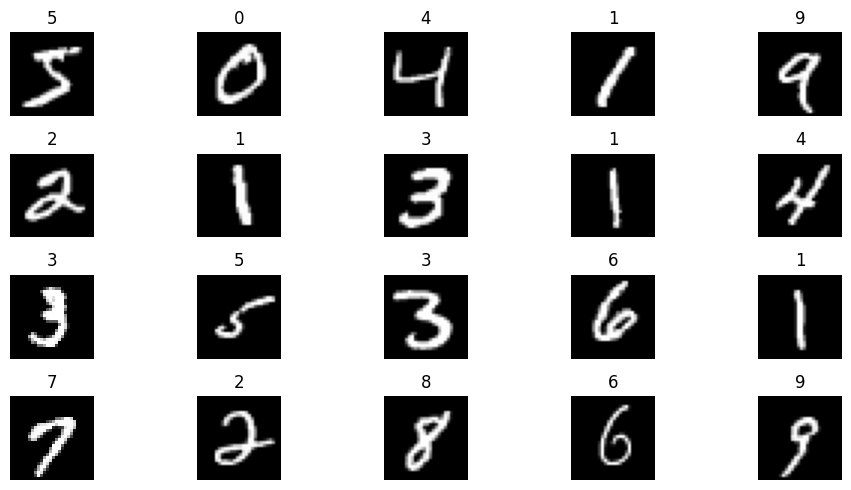

In [11]:
plt.figure(figsize=(10, 5))
for i in range(20):
    ax = plt.subplot(4, 5, i + 1)
    ax.imshow(mnist_train_images[i].squeeze(), cmap='gray')
    ax.set_title(str(mnist_train_labels[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

### Step 11 - Build the CNN Model

Dua convolutional layer dengan max pooling, lalu dense 128 neuron dan dropout 0.5 sebelum
output 10 neuron. Dropout sebelum output penting karena dense layer pada MNIST sangat rawan
overfitting.

In [12]:
mnist_model = keras.Sequential(
    [
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(10),
    ],
    name='mnist_cnn',
)

mnist_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

mnist_model.summary()

D:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Step 12 - Train the Model

In [13]:
mnist_train_ds = (
    tf.data.Dataset.from_tensor_slices((mnist_train_images, mnist_train_labels))
    .shuffle(10_000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

mnist_test_ds = (
    tf.data.Dataset.from_tensor_slices((mnist_test_images, mnist_test_labels))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

start = time.time()
mnist_history = mnist_model.fit(
    mnist_train_ds,
    validation_data=mnist_test_ds,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=3, restore_best_weights=True
    )],
    verbose=2,
)
elapsed = time.time() - start

print(f'Waktu pelatihan: {elapsed:.1f} detik ({elapsed / 60:.1f} menit)')

Epoch 1/10


469/469 - 21s - 46ms/step - accuracy: 0.9074 - loss: 0.3029 - val_accuracy: 0.9810 - val_loss: 0.0632


Epoch 2/10


469/469 - 16s - 35ms/step - accuracy: 0.9715 - loss: 0.0960 - val_accuracy: 0.9861 - val_loss: 0.0447


Epoch 3/10


469/469 - 16s - 35ms/step - accuracy: 0.9803 - loss: 0.0677 - val_accuracy: 0.9871 - val_loss: 0.0385


... (9 outputs left out)

469/469 - 19s - 41ms/step - accuracy: 0.9904 - loss: 0.0318 - val_accuracy: 0.9901 - val_loss: 0.0286


Epoch 9/10


469/469 - 19s - 41ms/step - accuracy: 0.9918 - loss: 0.0273 - val_accuracy: 0.9913 - val_loss: 0.0309


Waktu pelatihan: 165.6 detik (2.8 menit)


### Step 13 - Training Curves

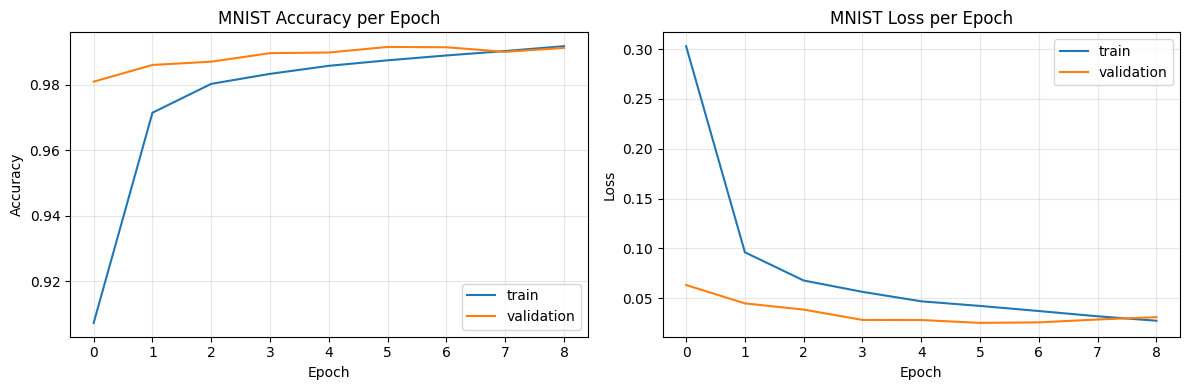

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(mnist_history.history['accuracy'], label='train')
axes[0].plot(mnist_history.history['val_accuracy'], label='validation')
axes[0].set_title('MNIST Accuracy per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(mnist_history.history['loss'], label='train')
axes[1].plot(mnist_history.history['val_loss'], label='validation')
axes[1].set_title('MNIST Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Step 14 - Evaluate the MNIST Model

In [15]:
mnist_loss, mnist_acc = mnist_model.evaluate(mnist_test_ds, verbose=0)
print(f'Test loss     : {mnist_loss:.4f}')
print(f'Test accuracy : {mnist_acc:.4f}')

Test loss     : 0.0252
Test accuracy : 0.9916


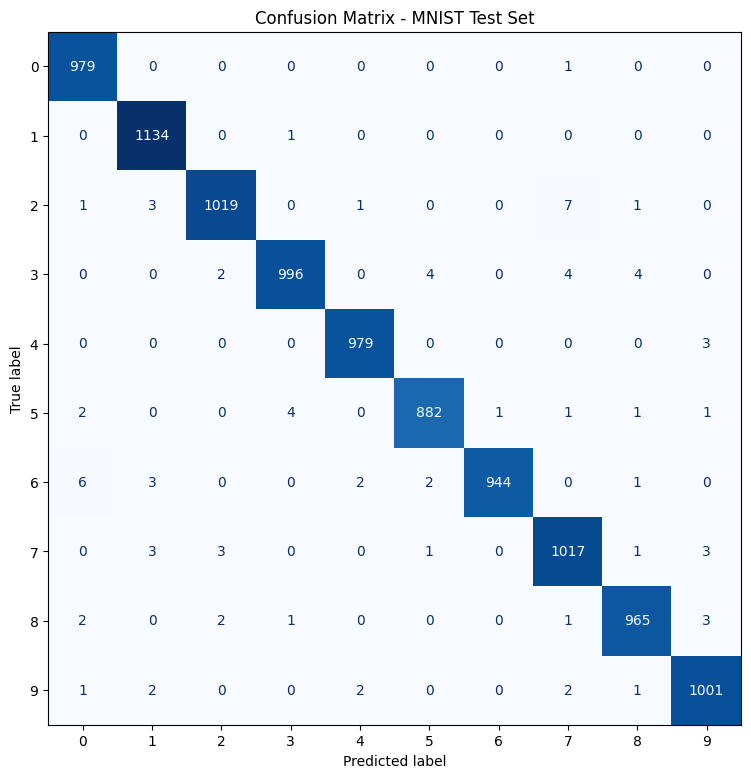

              precision    recall  f1-score   support

           0     0.9879    0.9990    0.9934       980
           1     0.9904    0.9991    0.9947      1135
           2     0.9932    0.9874    0.9903      1032
           3     0.9940    0.9861    0.9901      1010
           4     0.9949    0.9969    0.9959       982
           5     0.9921    0.9888    0.9905       892
           6     0.9989    0.9854    0.9921       958
           7     0.9845    0.9893    0.9869      1028
           8     0.9908    0.9908    0.9908       974
           9     0.9901    0.9921    0.9911      1009

    accuracy                         0.9916     10000
   macro avg     0.9917    0.9915    0.9916     10000
weighted avg     0.9916    0.9916    0.9916     10000



In [16]:
mnist_prob = mnist_model.predict(mnist_test_ds, verbose=0)
mnist_pred = np.argmax(mnist_prob, axis=1)

cm = confusion_matrix(mnist_test_labels, mnist_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[str(i) for i in range(10)])
fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
plt.title('Confusion Matrix - MNIST Test Set')
plt.show()

print(classification_report(mnist_test_labels, mnist_pred, digits=4))

In [17]:
for digit in range(10):
    mask = mnist_test_labels == digit
    print(f'Digit {digit}: {accuracy_score(mnist_test_labels[mask], mnist_pred[mask]):.4f} '
          f'({mask.sum()} citra)')

Digit 0: 0.9990 (980 citra)
Digit 1: 0.9991 (1135 citra)
Digit 2: 0.9874 (1032 citra)
Digit 3: 0.9861 (1010 citra)
Digit 4: 0.9969 (982 citra)
Digit 5: 0.9888 (892 citra)
Digit 6: 0.9854 (958 citra)
Digit 7: 0.9893 (1028 citra)
Digit 8: 0.9908 (974 citra)
Digit 9: 0.9921 (1009 citra)


### Step 15 - Inspect Misclassified Digits

Digit yang salah biasanya yang penulisannya ambigu, misalnya 4 dan 9, 3 dan 5, atau 7 dan 1.

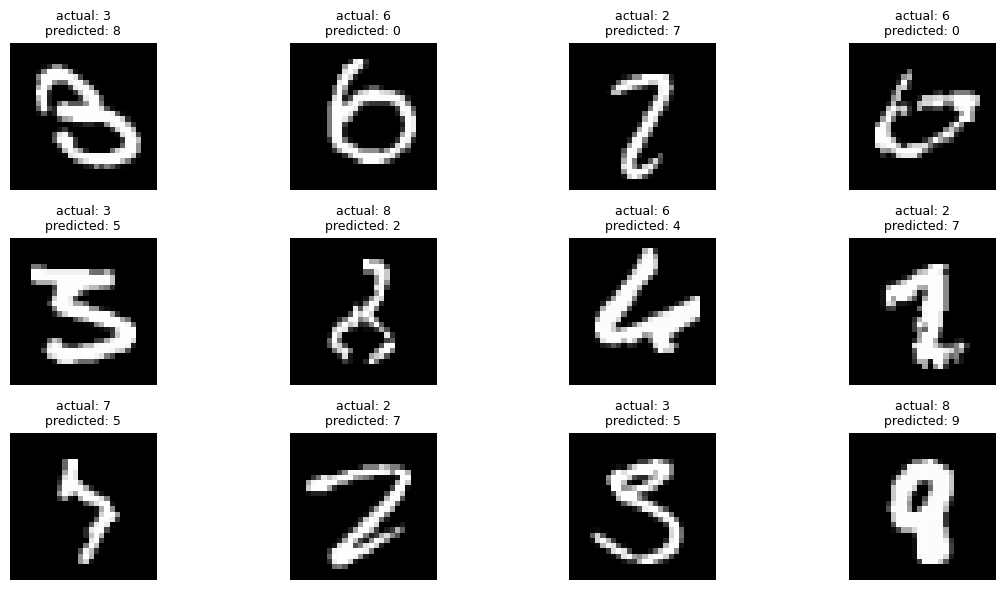

In [18]:
wrong = np.where(mnist_pred != mnist_test_labels)[0]
sample = wrong[:12]

plt.figure(figsize=(12, 6))
for i, idx in enumerate(sample):
    ax = plt.subplot(3, 4, i + 1)
    ax.imshow(mnist_test_images[idx].squeeze(), cmap='gray')
    ax.set_title(f'actual: {mnist_test_labels[idx]}\npredicted: {mnist_pred[idx]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Conclusion

Kedua tugas jobsheet selesai dengan hasil sebagai berikut.

**Part A - CIFAR-10.** Model CNN yang dimodifikasi mencapai akurasi uji **0.8161** pada 10.000
citra, melewati target 80%. Peningkatan dari model Lab 2 (0.6845) sebesar 13.16 poin persen
diperoleh dari empat perubahan: augmentasi flip, translasi, dan zoom; batch normalization pada
setiap convolutional layer; dropout bertingkat 0.1 sampai 0.3; serta arsitektur yang lebih dalam
dengan dua conv layer pada blok pertama dan kedua.

Percobaan pertama gagal total dengan akurasi uji 0.6942 karena `RandomRotation(0.1)`. Pada Keras 3
argumen `factor` layer tersebut adalah fraksi dari 2 pi, sehingga 0.1 berarti rotasi sampai 36
derajat. Akurasi latih epoch pertama hanya 0.3430, lebih rendah daripada model Lab 2 tanpa
augmentasi. Setelah rotasi dihapus dan dropout diturunkan, akurasi latih epoch pertama naik
menjadi 0.4313 dan terus naik secara konsisten.

Kelas yang paling sulit adalah **cat** (0.6180) dan **dog** (0.6860). Keduanya sering tertukar
karena bentuk tubuh dan tekstur bulu yang mirip pada resolusi 32x32. Kelas termudah adalah
**frog** (0.9470) dan **automobile** (0.9460) yang punya bentuk dan warna khas.

**Part B - MNIST.** Model CNN dua blok konvolusi mencapai akurasi uji **0.9916** dengan loss
0.0252, hanya 84 citra salah dari 10.000. Pelatihan berhenti di epoch 9 karena `EarlyStopping`
dengan patience 3, lalu bobot dikembalikan ke epoch 6 yang punya akurasi validasi terbaik
(0.9916). Digit paling mudah dikenali adalah **1** (0.9991) dan **0** (0.9990), sedangkan yang
paling sulit adalah **6** (0.9854) dan **3** (0.9861) karena variasi bentuk keduanya cukup besar.

Perbedaan tingkat kesulitan antara CIFAR-10 dan MNIST sangat mencolok, 0.8161 berbanding 0.9916.
Penyebabnya bukan kapasitas model, melainkan karakter data. Citra MNIST punya latar belakang
bersih, satu objek di tengah, dan hanya skala abu-abu, sehingga fitur yang perlu dipelajari jauh
lebih sedikit. Citra CIFAR-10 berwarna, berlatar belakang bebas, dan objeknya bisa berada di mana
saja dengan sudut pandang apa pun, sehingga tugasnya secara inheren lebih sulit pada resolusi
yang sama.

Untuk peningkatan lebih lanjut pada CIFAR-10, langkah yang paling menjanjikan adalah menambah
kedalaman jaringan, memakai `GlobalAveragePooling2D` untuk mengurangi parameter di bagian
klasifikasi, dan menerapkan learning rate warmup. Pelatihan juga akan jauh lebih cepat pada GPU
karena seluruh proses di sini berjalan di CPU.